# Olist E-Commerce Data Exploration

## 1. Importing Libraries

This notebook explores the Olist Brazilian E-Commerce dataset to understand its structure, data quality, and key characteristics.

In [13]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from IPython.display import display

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

sns.set_theme(style="whitegrid")

print("All libraries imported successfully!")

All libraries imported successfully!


## 2. Loading the Datasets

In [14]:
DATA_PATH = Path("../data/raw")

customers = pd.read_csv(DATA_PATH / "olist_customers_dataset.csv")
geolocation = pd.read_csv(DATA_PATH / "olist_geolocation_dataset.csv")
order_items = pd.read_csv(DATA_PATH / "olist_order_items_dataset.csv")
order_payments = pd.read_csv(DATA_PATH / "olist_order_payments_dataset.csv")
order_reviews = pd.read_csv(DATA_PATH / "olist_order_reviews_dataset.csv")
orders = pd.read_csv(DATA_PATH / "olist_orders_dataset.csv")
products = pd.read_csv(DATA_PATH / "olist_products_dataset.csv")
sellers = pd.read_csv(DATA_PATH / "olist_sellers_dataset.csv")
category_translation = pd.read_csv(
    DATA_PATH / "product_category_name_translation.csv"
)

datasets = {
    "Customers": customers,
    "Geolocation": geolocation,
    "Order Items": order_items,
    "Order Payments": order_payments,
    "Order Reviews": order_reviews,
    "Orders": orders,
    "Products": products,
    "Sellers": sellers,
    "Category Translation": category_translation
}

print("All nine datasets loaded successfully!")

All nine datasets loaded successfully!


## 3. Dataset Dimensions

In [15]:
dataset_summary = pd.DataFrame({
    "Dataset": list(datasets.keys()),
    "Rows": [df.shape[0] for df in datasets.values()],
    "Columns": [df.shape[1] for df in datasets.values()]
})

display(dataset_summary)

,Dataset,Rows,Columns
0,Customers,99441,5
1,Geolocation,1000163,5
2,Order Items,112650,7
3,Order Payments,103886,5
4,Order Reviews,99224,7
5,Orders,99441,8
6,Products,32951,9
7,Sellers,3095,4
8,Category Translation,71,2


## 4. Dataset Structure and Data Types

Inspect the columns, data types, and non-null record counts in each dataset.

In [16]:
# Display structure of all datasets

for name, df in datasets.items():
    print(f"\n{'=' * 60}")
    print(f"DATASET: {name}")
    print(f"{'=' * 60}")
    df.info()


DATASET: Customers
<class 'pandas.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 5 columns):
 #   Column                    Non-Null Count  Dtype
---  ------                    --------------  -----
 0   customer_id               99441 non-null  str  
 1   customer_unique_id        99441 non-null  str  
 2   customer_zip_code_prefix  99441 non-null  int64
 3   customer_city             99441 non-null  str  
 4   customer_state            99441 non-null  str  
dtypes: int64(1), str(4)
memory usage: 3.8 MB

DATASET: Geolocation
<class 'pandas.DataFrame'>
RangeIndex: 1000163 entries, 0 to 1000162
Data columns (total 5 columns):
 #   Column                       Non-Null Count    Dtype  
---  ------                       --------------    -----  
 0   geolocation_zip_code_prefix  1000163 non-null  int64  
 1   geolocation_lat              1000163 non-null  float64
 2   geolocation_lng              1000163 non-null  float64
 3   geolocation_city             1000163 n

## 5. Previewing Dataset Records

In [17]:
# Display first five records from each dataset

for name, df in datasets.items():
    print(f"\n{name}")
    display(df.head())


Customers


,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,9790,sao bernardo do campo,SP
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,1151,sao paulo,SP
3,b2b6027bc5c5109e529d4dc6358b12c3,259dac757896d24d7702b9acbbff3f3c,8775,mogi das cruzes,SP
4,4f2d8ab171c80ec8364f7c12e35b23ad,345ecd01c38d18a9036ed96c73b8d066,13056,campinas,SP



Geolocation


,geolocation_zip_code_prefix,geolocation_lat,geolocation_lng,geolocation_city,geolocation_state
0,1037,-23.545621,-46.639292,sao paulo,SP
1,1046,-23.546081,-46.644820,sao paulo,SP
2,1046,-23.546129,-46.642951,sao paulo,SP
3,1041,-23.544392,-46.639499,sao paulo,SP
4,1035,-23.541578,-46.641607,sao paulo,SP



Order Items


,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14


... (8 outputs left out)


Sellers


,seller_id,seller_zip_code_prefix,seller_city,seller_state
0,3442f8959a84dea7ee197c632cb2df15,13023,campinas,SP
1,d1b65fc7debc3361ea86b5f14c68d2e2,13844,mogi guacu,SP
2,ce3ad9de960102d0677a81f5d0bb7b2d,20031,rio de janeiro,RJ
3,c0f3eea2e14555b6faeea3dd58c1b1c3,4195,sao paulo,SP
4,51a04a8a6bdcb23deccc82b0b80742cf,12914,braganca paulista,SP



Category Translation


,product_category_name,product_category_name_english
0,beleza_saude,health_beauty
1,informatica_acessorios,computers_accessories
2,automotivo,auto
3,cama_mesa_banho,bed_bath_table
4,moveis_decoracao,furniture_decor


## 6. Missing Value Analysis

Identify missing values in each dataset and calculate their percentage to assess data completeness.

In [18]:
# Missing value analysis

missing_summary = []

for name, df in datasets.items():
    for column in df.columns:
        missing_count = df[column].isnull().sum()
        missing_percentage = (missing_count / len(df)) * 100

        missing_summary.append({
            "Dataset": name,
            "Column": column,
            "Missing Values": missing_count,
            "Missing Percentage": round(missing_percentage, 2)
        })

missing_df = pd.DataFrame(missing_summary)

missing_df = missing_df[missing_df["Missing Values"] > 0]

display(missing_df)

,Dataset,Column,Missing Values,Missing Percentage
25,Order Reviews,review_comment_title,87656,88.34
26,Order Reviews,review_comment_message,58247,58.70
33,Orders,order_approved_at,160,0.16
34,Orders,order_delivered_carrier_date,1783,1.79
35,Orders,order_delivered_customer_date,2965,2.98
38,Products,product_category_name,610,1.85
39,Products,product_name_lenght,610,1.85
40,Products,product_description_lenght,610,1.85
41,Products,product_photos_qty,610,1.85
42,Products,product_weight_g,2,0.01


## 7. Duplicate Record Analysis

Check the number of completely duplicated rows in each dataset.

In [19]:
# Duplicate record analysis

duplicate_summary = []

for name, df in datasets.items():
    duplicate_count = df.duplicated().sum()

    duplicate_summary.append({
        "Dataset": name,
        "Total Records": len(df),
        "Duplicate Records": duplicate_count
    })

duplicate_df = pd.DataFrame(duplicate_summary)

display(duplicate_df)

,Dataset,Total Records,Duplicate Records
0,Customers,99441,0
1,Geolocation,1000163,261831
2,Order Items,112650,0
3,Order Payments,103886,0
4,Order Reviews,99224,0
5,Orders,99441,0
6,Products,32951,0
7,Sellers,3095,0
8,Category Translation,71,0


## 8. Statistical Summary

Generate descriptive statistics for numerical columns to understand the distribution of the data.

In [20]:
# Statistical summary of numerical columns

for name, df in datasets.items():
    numerical_data = df.select_dtypes(include=np.number)

    if not numerical_data.empty:
        print(f"\nStatistical Summary: {name}")
        display(numerical_data.describe().round(2))


Statistical Summary: Customers


,customer_zip_code_prefix
count,99441.00
mean,35137.47
std,29797.94
min,1003.00
25%,11347.00
50%,24416.00
75%,58900.00
max,99990.00



Statistical Summary: Geolocation


,geolocation_zip_code_prefix,geolocation_lat,geolocation_lng
count,1000163.00,1000163.00,1000163.00
mean,36574.17,-21.18,-46.39
std,30549.34,5.72,4.27
min,1001.00,-36.61,-101.47
25%,11075.00,-23.60,-48.57
50%,26530.00,-22.92,-46.64
75%,63504.00,-19.98,-43.77
max,99990.00,45.07,121.11



Statistical Summary: Order Items


,order_item_id,price,freight_value
count,112650.00,112650.00,112650.00
mean,1.20,120.65,19.99
std,0.71,183.63,15.81
min,1.00,0.85,0.00
25%,1.00,39.90,13.08
50%,1.00,74.99,16.26
75%,1.00,134.90,21.15
max,21.00,6735.00,409.68


... (4 outputs left out)


Statistical Summary: Products


,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
count,32341.00,32341.00,32341.00,32949.00,32949.00,32949.00,32949.00
mean,48.48,771.50,2.19,2276.47,30.82,16.94,23.20
std,10.25,635.12,1.74,4282.04,16.91,13.64,12.08
min,5.00,4.00,1.00,0.00,7.00,2.00,6.00
25%,42.00,339.00,1.00,300.00,18.00,8.00,15.00
50%,51.00,595.00,1.00,700.00,25.00,13.00,20.00
75%,57.00,972.00,3.00,1900.00,38.00,21.00,30.00
max,76.00,3992.00,20.00,40425.00,105.00,105.00,118.00



Statistical Summary: Sellers


,seller_zip_code_prefix
count,3095.00
mean,32291.06
std,32713.45
min,1001.00
25%,7093.50
50%,14940.00
75%,64552.50
max,99730.00


## 9. Data Quality Findings

The initial data-quality analysis identified the following observations:

### Missing Values
- The `review_comment_title` column contains 87,656 missing values (88.34%).
- The `review_comment_message` column contains 58,247 missing values (58.70%).
- The Orders dataset contains missing delivery timestamps, mainly because some orders were not delivered.
- The Products dataset contains missing category and product attribute information.
- Two product records have missing physical dimension and weight information.

### Duplicate Records
- The Geolocation dataset contains 261,831 completely duplicated rows.
- The remaining eight datasets contain no completely duplicated rows.
- Duplicate geolocation records will be investigated during data cleaning.

### Conclusion
The datasets are generally well structured, but missing values and duplicate geolocation records require attention before further analysis. Missing values will not be removed blindly because some represent legitimate business conditions.

## 10. Exploratory Data Visualizations

### Order Status Distribution

Analyze the distribution of orders across different order statuses.

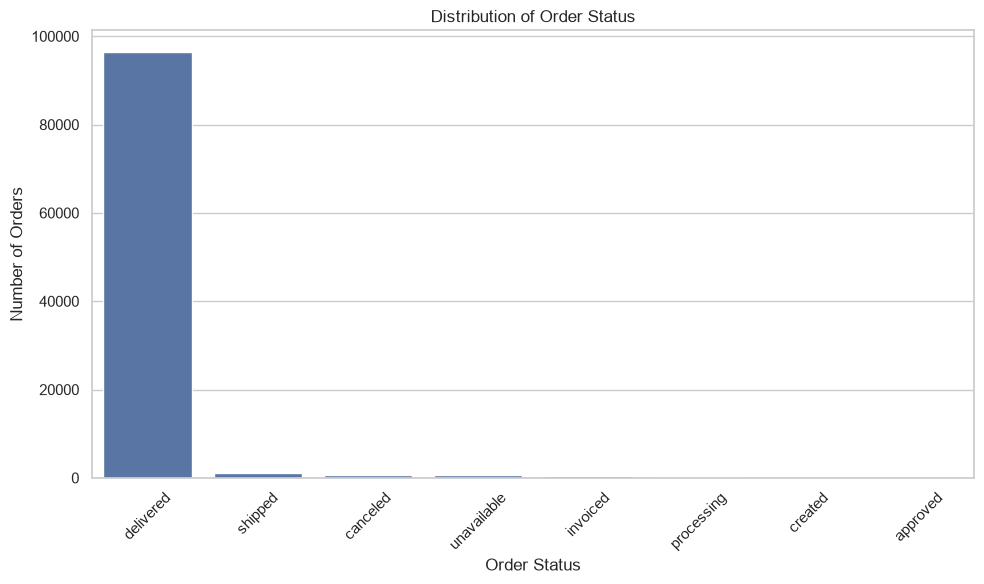

In [21]:
# Order status distribution

status_counts = orders["order_status"].value_counts()

plt.figure(figsize=(10, 6))

sns.barplot(
    x=status_counts.index,
    y=status_counts.values
)

plt.title("Distribution of Order Status")
plt.xlabel("Order Status")
plt.ylabel("Number of Orders")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

### Monthly Order Trend

Examine how the number of orders changes over time.

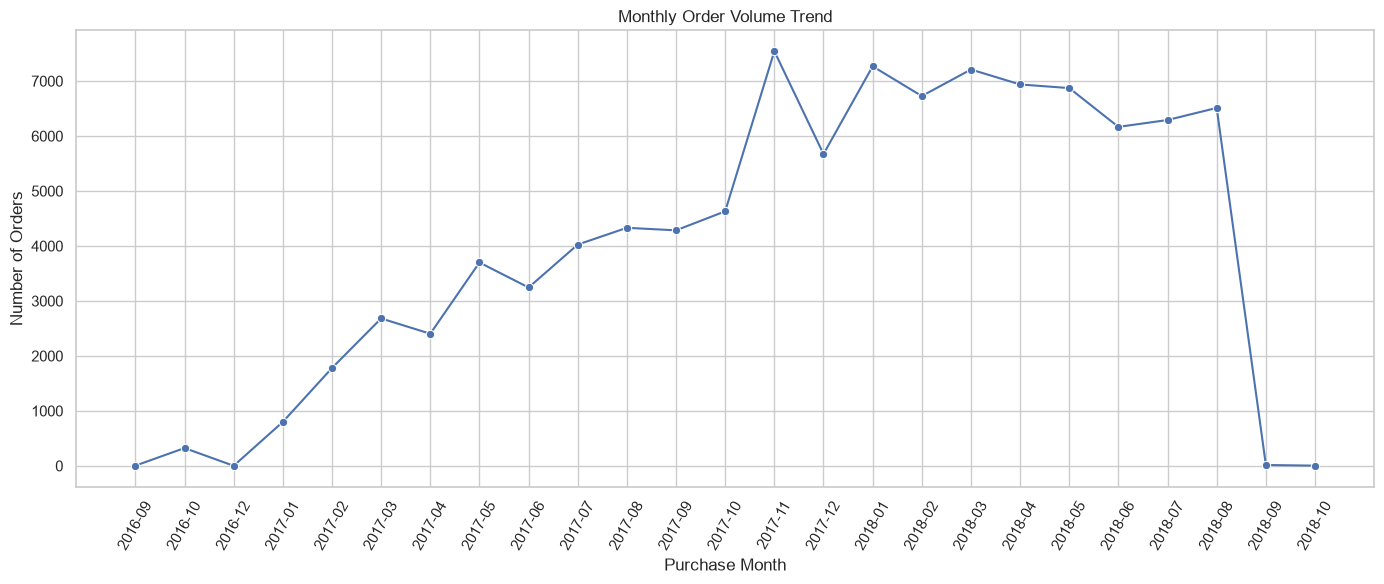

In [22]:
# Convert purchase timestamp to datetime

orders["order_purchase_timestamp"] = pd.to_datetime(
    orders["order_purchase_timestamp"],
    errors="coerce"
)

# Extract purchase month

orders["purchase_month"] = (
    orders["order_purchase_timestamp"].dt.to_period("M")
)

monthly_orders = (
    orders.groupby("purchase_month")["order_id"]
    .nunique()
    .reset_index(name="total_orders")
)

monthly_orders["purchase_month"] = (
    monthly_orders["purchase_month"].astype(str)
)

plt.figure(figsize=(14, 6))

sns.lineplot(
    data=monthly_orders,
    x="purchase_month",
    y="total_orders",
    marker="o"
)

plt.title("Monthly Order Volume Trend")
plt.xlabel("Purchase Month")
plt.ylabel("Number of Orders")
plt.xticks(rotation=60)

plt.tight_layout()
plt.show()

## 11. Product Category Analysis

Analyze product sales across categories to identify the categories generating the highest product revenue.v

In [23]:
# Merge order items with product information

category_data = order_items.merge(
    products[["product_id", "product_category_name"]],
    on="product_id",
    how="left"
)

# Add English category names

category_data = category_data.merge(
    category_translation,
    on="product_category_name",
    how="left"
)

# Calculate revenue by category

category_revenue = (
    category_data.groupby("product_category_name_english")["price"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
    .reset_index()
)

category_revenue.columns = ["Product Category", "Revenue"]

display(category_revenue)

,Product Category,Revenue
0,health_beauty,1258681.34
1,watches_gifts,1205005.68
2,bed_bath_table,1036988.68
3,sports_leisure,988048.97
4,computers_accessories,911954.32
5,furniture_decor,729762.49
6,cool_stuff,635290.85
7,housewares,632248.66
8,auto,592720.11
9,garden_tools,485256.46


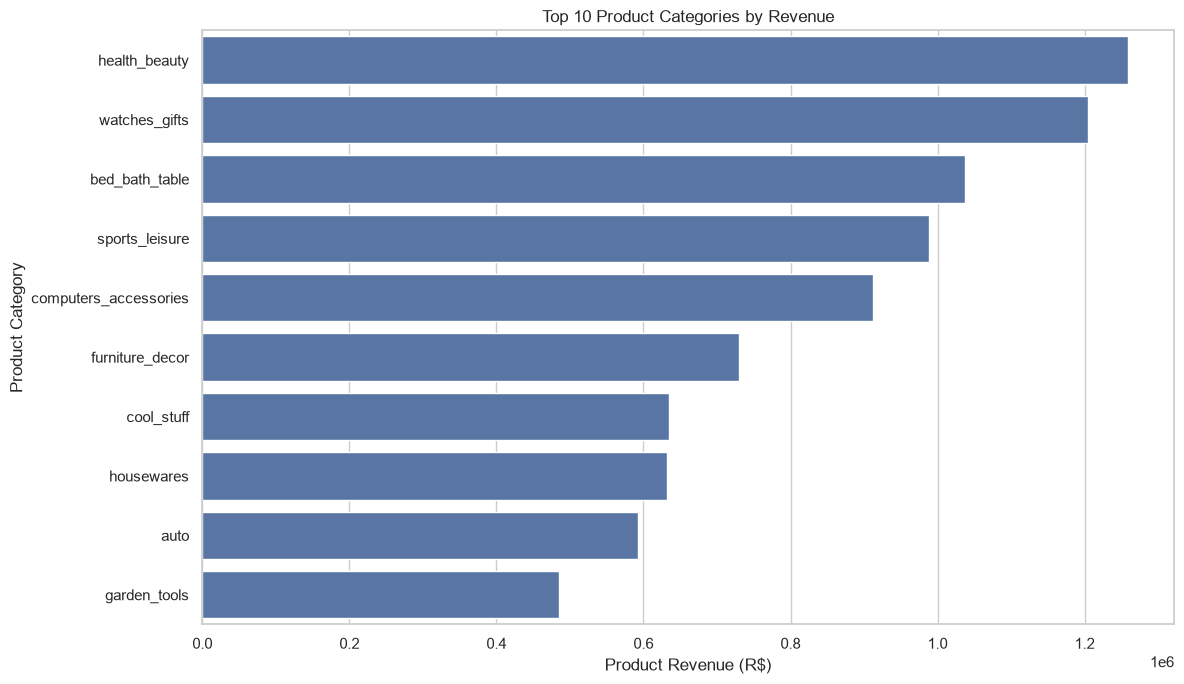

In [24]:
plt.figure(figsize=(12, 7))

sns.barplot(
    data=category_revenue,
    x="Revenue",
    y="Product Category"
)

plt.title("Top 10 Product Categories by Revenue")
plt.xlabel("Product Revenue (R$)")
plt.ylabel("Product Category")

plt.tight_layout()
plt.show()

## 12. Overall Data Exploration Summary

The exploratory analysis of the Olist Brazilian E-Commerce dataset produced the following findings:

1. The project uses nine datasets containing customer, order, product, seller, payment, review, and geolocation information.
2. The Orders dataset contains 99,441 records, while the Order Items dataset contains 112,650 records.
3. The Geolocation dataset contains 1,000,163 records and has 261,831 completely duplicated rows.
4. Review comments contain a substantial number of missing values.
5. Missing delivery timestamps and product attributes require careful treatment during data cleaning.
6. Order status and monthly order trends provide an overview of business activity.
7. Product category revenue analysis helps identify the major revenue-generating categories.

### Conclusion

The exploratory analysis provides an understanding of the dataset structure, completeness, duplicates, and business distributions. These findings establish the foundation for the next stage: data cleaning and preparation.